In [1]:
%%writefile brain_tumor_segmentation.py
"""
brain_tumor_segmentation.py
===========================
Core ML module for automated brain tumour detection & segmentation
from multi-modal MRI scans (BraTS 2021).
"""

import os
import re
import tarfile
import numpy as np
import nibabel as nib

import torch
import torch.nn as nn
import torch.nn.functional as F

from scipy.ndimage import gaussian_filter, zoom
from scipy.spatial.distance import directed_hausdorff

LOCAL_ROOT = os.environ.get("BRATS_LOCAL_ROOT", "./BraTS2021_Training_Data")
TARGET_SIZE = 128

LABELS = {
    0: "Background",
    1: "Necrotic Core",
    2: "Edema",
    3: "Enhancing Tumor",  # Remapped from original BraTS label 4
}
MODALITIES = ["t1", "t1ce", "t2", "flair"]

def is_kaggle():
    return os.path.exists("/kaggle/input")

def find_kaggle_tar():
    root = "/kaggle/input"
    if not os.path.isdir(root):
        return None
    queue = [(root, 0)]
    while queue:
        cur, depth = queue.pop(0)
        if depth > 4:
            continue
        try:
            entries = sorted(os.listdir(cur))
        except OSError:
            continue
        for name in entries:
            if name.endswith(".tar") and "training" in name.lower():
                return os.path.join(cur, name)
            full = os.path.join(cur, name)
            if os.path.isdir(full) and depth < 4:
                queue.append((full, depth + 1))
    return None

def _discover_kaggle_patient_root(max_depth=4):
    root = "/kaggle/input"
    if not os.path.isdir(root):
        return None
    queue = [(root, 0)]
    while queue:
        cur, depth = queue.pop(0)
        if depth > max_depth:
            continue
        try:
            entries = sorted(os.listdir(cur))
        except OSError:
            continue
        patient_dirs = [d for d in entries if re.match(r"^BraTS2021_\d{5}$", d)]
        if patient_dirs:
            return cur
        for name in entries:
            full = os.path.join(cur, name)
            if os.path.isdir(full) and depth < max_depth:
                queue.append((full, depth + 1))
    return None

def get_data_source():
    if is_kaggle():
        root = _discover_kaggle_patient_root()
        if root:
            return None, root
        tar = find_kaggle_tar()
        if tar:
            return tar, None
        return None, None
    return None, get_local_root()

def get_tar_path():
    tar, _ = get_data_source()
    return tar

def get_local_root():
    return LOCAL_ROOT

def _match_patient_dir(name):
    m = re.search(r"BraTS2021_\d{5}", name)
    return m.group(0) if m else None

def get_patient_ids(tar_path=None, local_root=None):
    if tar_path is not None and os.path.exists(tar_path):
        ids = []
        with tarfile.open(tar_path, "r") as tar:
            seen = set()
            for member in tar.getmembers():
                pid = _match_patient_dir(member.name)
                if pid and pid not in seen:
                    seen.add(pid)
                    ids.append(pid)
        return sorted(ids)

    if local_root is None:
        local_root = get_local_root()
    if os.path.isdir(local_root):
        return sorted(
            d for d in os.listdir(local_root)
            if re.match(r"^BraTS2021_\d{5}$", d)
        )

    raise FileNotFoundError("No dataset found.")

def _extract_patient_files(patient_id, tar_path=None, local_root=None, work_dir=None):
    if tar_path is not None and os.path.exists(tar_path):
        if work_dir is None:
            work_dir = os.path.join(os.getcwd(), ".brats_cache")
        os.makedirs(work_dir, exist_ok=True)
        patient_dir = os.path.join(work_dir, patient_id)
        if not os.path.exists(patient_dir):
            with tarfile.open(tar_path, "r") as tar:
                members = [
                    m for m in tar.getmembers()
                    if _match_patient_dir(m.name) == patient_id
                ]
                tar.extractall(path=work_dir, members=members)
        search_root = work_dir
    else:
        if local_root is None:
            local_root = get_local_root()
        search_root = local_root

    files = {}
    for root, _, filenames in os.walk(search_root):
        if patient_id in root or any(patient_id in f for f in filenames):
            for f in filenames:
                if patient_id in f and f.endswith(".nii.gz"):
                    for mod in MODALITIES:
                        if f"_{mod}.nii.gz" in f:
                            files[mod] = os.path.join(root, f)
                    if "_seg.nii.gz" in f:
                        files["seg"] = os.path.join(root, f)

    if len(files) < 5:
        case_path = os.path.join(search_root, patient_id, patient_id)
        for mod in MODALITIES:
            files[mod] = f"{case_path}_{mod}.nii.gz"
        files["seg"] = f"{case_path}_seg.nii.gz"

    return files

def load_patient_volume(patient_id, tar_path=None, local_root=None, work_dir=None):
    files = _extract_patient_files(patient_id, tar_path, local_root, work_dir)
    modalities = {}
    for mod in MODALITIES:
        modalities[mod] = nib.load(files[mod]).get_fdata().astype(np.float32)
    seg = nib.load(files["seg"]).get_fdata().astype(np.int16)
    # Remap BraTS label 4 to contiguous label index 3
    seg[seg == 4] = 3
    return modalities, seg

def zscore_normalize(volume):
    mean, std = volume.mean(), volume.std()
    return (volume - mean) / std if std >= 1e-6 else np.zeros_like(volume)

def brain_mask_from_t2(t2, threshold=0.15, sigma=1.0):
    raw = (t2 - t2.min()) / (t2.max() - t2.min() + 1e-8)
    mask = gaussian_filter((raw > threshold).astype(np.float32), sigma=sigma)
    return (mask > 0.5).astype(np.float32)

def crop_to_bbox(volume, mask):
    idx = np.argwhere(mask > 0)
    if len(idx) == 0:
        return volume, (slice(None), slice(None), slice(None))
    zmin, ymin, xmin = idx.min(axis=0)
    zmax, ymax, xmax = idx.max(axis=0) + 1
    slc = (slice(zmin, zmax), slice(ymin, ymax), slice(xmin, xmax))
    return volume[slc], slc

def resample_volume(volume, target_size=TARGET_SIZE):
    factors = [target_size / s for s in volume.shape]
    return zoom(volume, factors, order=1)

def preprocess_patient(patient_id, tar_path=None, local_root=None, work_dir=None, target_size=TARGET_SIZE):
    modalities, seg = load_patient_volume(patient_id, tar_path, local_root, work_dir)
    mask = brain_mask_from_t2(modalities["t2"])
    cropped = {m: crop_to_bbox(modalities[m], mask)[0] for m in MODALITIES}
    seg_cropped, _ = crop_to_bbox(seg, mask)

    resampled = {m: resample_volume(cropped[m], target_size) for m in MODALITIES}
    seg_resampled = np.round(resample_volume(seg_cropped.astype(np.float32), target_size)).astype(np.int16)
    stack = np.stack([zscore_normalize(resampled[m]) for m in MODALITIES], axis=0)
    return stack, seg_resampled

class ConvBlock3D(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm3d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv3d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm3d(out_ch),
            nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.block(x)

class Encoder3D(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = ConvBlock3D(in_ch, out_ch)
        self.pool = nn.MaxPool3d(kernel_size=2, stride=2)
    def forward(self, x):
        feat = self.conv(x)
        return feat, self.pool(feat)

class Decoder3D(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.up = nn.ConvTranspose3d(in_ch, out_ch, kernel_size=2, stride=2)
        self.conv = ConvBlock3D(out_ch + skip_ch, out_ch)
    def forward(self, x, skip):
        x = self.up(x)
        if x.shape[2:] != skip.shape[2:]:
            diff = [skip.shape[i] - x.shape[i] for i in (2, 3, 4)]
            x = F.pad(x, [diff[2]//2, diff[2]-diff[2]//2, diff[1]//2, diff[1]-diff[1]//2, diff[0]//2, diff[0]-diff[0]//2])
        return self.conv(torch.cat([x, skip], dim=1))

class UNet3D(nn.Module):
    def __init__(self, in_channels=4, out_channels=4, base=32):
        super().__init__()
        self.enc1 = Encoder3D(in_channels, base)
        self.enc2 = Encoder3D(base, base * 2)
        self.enc3 = Encoder3D(base * 2, base * 4)
        self.enc4 = Encoder3D(base * 4, base * 8)
        self.bottleneck = ConvBlock3D(base * 8, base * 16)
        self.dec4 = Decoder3D(base * 16, base * 8, base * 8)
        self.dec3 = Decoder3D(base * 8, base * 4, base * 4)
        self.dec2 = Decoder3D(base * 4, base * 2, base * 2)
        self.dec1 = Decoder3D(base * 2, base, base)
        self.out_conv = nn.Conv3d(base, out_channels, kernel_size=1)

    def forward(self, x):
        f1, p1 = self.enc1(x)
        f2, p2 = self.enc2(p1)
        f3, p3 = self.enc3(p2)
        f4, p4 = self.enc4(p3)
        b = self.bottleneck(p4)
        d4 = self.dec4(b, f4)
        d3 = self.dec3(d4, f3)
        d2 = self.dec2(d3, f2)
        d1 = self.dec1(d2, f1)
        return self.out_conv(d1)

def dice_loss(pred_logits, target, smooth=1.0):
    num_classes = pred_logits.shape[1]
    pred = F.softmax(pred_logits, dim=1)
    target_onehot = F.one_hot(target.long(), num_classes=num_classes).permute(0, 4, 1, 2, 3).float()
    dims = (2, 3, 4)
    intersection = (pred * target_onehot).sum(dim=dims)
    union = pred.sum(dim=dims) + target_onehot.sum(dim=dims)
    dice = (2.0 * intersection + smooth) / (union + smooth)
    return 1.0 - dice.mean(dim=0)[1:].mean()

def hybrid_loss(pred_logits, target, ce_weight=1.0, dice_weight=1.0):
    return ce_weight * F.cross_entropy(pred_logits, target.long()) + dice_weight * dice_loss(pred_logits, target)

def dice_score(pred, target, class_id):
    p, t = (pred == class_id).astype(np.float32), (target == class_id).astype(np.float32)
    union = p.sum() + t.sum()
    return 1.0 if union == 0 else (2.0 * (p * t).sum() / union)

def hausdorff_distance(pred, target, class_id):
    p, t = np.argwhere(pred == class_id), np.argwhere(target == class_id)
    if len(p) == 0 or len(t) == 0:
        return float("nan")
    if len(p) > 2000: p = p[np.random.choice(len(p), 2000, replace=False)]
    if len(t) > 2000: t = t[np.random.choice(len(t), 2000, replace=False)]
    return max(directed_hausdorff(p, t)[0], directed_hausdorff(t, p)[0])

def evaluate_patient(pred, target):
    pred_wt, target_wt = np.isin(pred, [1, 2, 3]).astype(np.uint8), np.isin(target, [1, 2, 3]).astype(np.uint8)
    pred_core, target_core = np.isin(pred, [1, 3]).astype(np.uint8), np.isin(target, [1, 3]).astype(np.uint8)
    return {
        "Whole Tumor": {"dice": dice_score(pred_wt, target_wt, 1), "hausdorff": hausdorff_distance(pred_wt, target_wt, 1)},
        "Tumor Core": {"dice": dice_score(pred_core, target_core, 1), "hausdorff": hausdorff_distance(pred_core, target_core, 1)},
        "Enhancing Tumor": {"dice": dice_score(pred, target, 3), "hausdorff": hausdorff_distance(pred, target, 3)},
    }

def prepare_training_data(patient_ids, tar_path=None, local_root=None, work_dir=None, target_size=TARGET_SIZE):
    X_list, Y_list = [], []
    for pid in patient_ids:
        stack, seg = preprocess_patient(pid, tar_path, local_root, work_dir, target_size)
        X_list.append(torch.from_numpy(stack).float())
        Y_list.append(torch.from_numpy(seg).long())
    return torch.stack(X_list), torch.stack(Y_list)

def train_unet3d(patient_ids, epochs=10, batch_size=1, lr=1e-3, val_split=0.2, tar_path=None, local_root=None, work_dir=None, target_size=TARGET_SIZE, checkpoint_path="artifacts/best_unet.pt", device=None, seed=42):
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    torch.manual_seed(seed)
    np.random.seed(seed)

    X, Y = prepare_training_data(patient_ids, tar_path, local_root, work_dir, target_size)
    n_val = max(1, int(len(X) * val_split))
    perm = torch.randperm(len(X))
    X_train, Y_train = X[perm[:-n_val]], Y[perm[:-n_val]]
    X_val, Y_val = X[perm[-n_val:]], Y[perm[-n_val:]]

    model = UNet3D(in_channels=4, out_channels=4).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", patience=3, factor=0.5)
    os.makedirs(os.path.dirname(checkpoint_path), exist_ok=True)

    history, best_val_loss = [], float("inf")
    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        for i in range(len(X_train)):
            x, y = X_train[i:i+batch_size].to(device), Y_train[i:i+batch_size].to(device)
            optimizer.zero_grad()
            loss = hybrid_loss(model(x), y)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
        train_loss /= len(X_train)

        model.eval()
        val_loss = 0.0
        val_dice = {"Whole Tumor": [], "Tumor Core": [], "Enhancing Tumor": []}
        with torch.no_grad():
            for i in range(len(X_val)):
                x, y = X_val[i:i+batch_size].to(device), Y_val[i:i+batch_size].to(device)
                out = model(x)
                val_loss += hybrid_loss(out, y).item()
                metrics = evaluate_patient(out.argmax(dim=1).cpu().numpy()[0], y.cpu().numpy()[0])
                for r, m in metrics.items():
                    if not np.isnan(m["dice"]): val_dice[r].append(m["dice"])

        val_loss /= len(X_val)
        scheduler.step(val_loss)
        avg_dice = {k: (np.mean(v) if v else float("nan")) for k, v in val_dice.items()}
        history.append({"epoch": epoch + 1, "train_loss": train_loss, "val_loss": val_loss, **{f"dice_{k.replace(' ', '_')}": v for k, v in avg_dice.items()}})

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), checkpoint_path)
        print(f"Epoch {epoch+1}/{epochs} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | WT Dice={avg_dice['Whole Tumor']:.4f}")

    model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    return model, history

def predict_patient(model, patient_id, tar_path=None, local_root=None, work_dir=None, target_size=TARGET_SIZE, device=None):
    if device is None: device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    stack, seg = preprocess_patient(patient_id, tar_path, local_root, work_dir, target_size)
    model.eval()
    with torch.no_grad():
        out = model(torch.from_numpy(stack)[None].float().to(device))
        pred = out.argmax(dim=1).cpu().numpy()[0]
    return pred, stack, seg

def load_model(checkpoint_path="artifacts/best_unet.pt", device=None):
    if device is None: device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = UNet3D(in_channels=4, out_channels=4)
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    return model.to(device).eval()

Overwriting brain_tumor_segmentation.py


In [2]:
!pip install -q nibabel scipy plotly

In [3]:
pip install nibabel scikit-image plotly scipy ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [4]:
import os
import numpy as np
import nibabel as nib
import plotly.graph_objects as go
import plotly.io as pio
from scipy.ndimage import gaussian_filter
from skimage import measure
import ipywidgets as widgets
from IPython.display import display, clear_output
import torch
import brain_tumor_segmentation as bts

pio.renderers.default = "notebook" if bts.is_kaggle() else "iframe"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TAR_PATH, KAGGLE_PATIENT_ROOT = bts.get_data_source()
LOCAL_ROOT = KAGGLE_PATIENT_ROOT or bts.get_local_root()
WORK_DIR = os.path.join(os.getcwd(), ".brats_cache")

print("Running on Kaggle:", bts.is_kaggle())
print("Tar path:", TAR_PATH)
print("Local root:", LOCAL_ROOT)
print("Device:", device)

Running on Kaggle: True
Tar path: /kaggle/input/datasets/dschettler8845/brats-2021-task1/BraTS2021_Training_Data.tar
Local root: ./BraTS2021_Training_Data
Device: cuda


In [5]:
PATIENT_IDS = bts.get_patient_ids(tar_path=TAR_PATH, local_root=LOCAL_ROOT)
print(f"Found {len(PATIENT_IDS)} patients")
print("First 10:", PATIENT_IDS[:10])

Found 1251 patients
First 10: ['BraTS2021_00000', 'BraTS2021_00002', 'BraTS2021_00003', 'BraTS2021_00005', 'BraTS2021_00006', 'BraTS2021_00008', 'BraTS2021_00009', 'BraTS2021_00011', 'BraTS2021_00012', 'BraTS2021_00014']


Preprocessed stack shape: (4, 128, 128, 128)


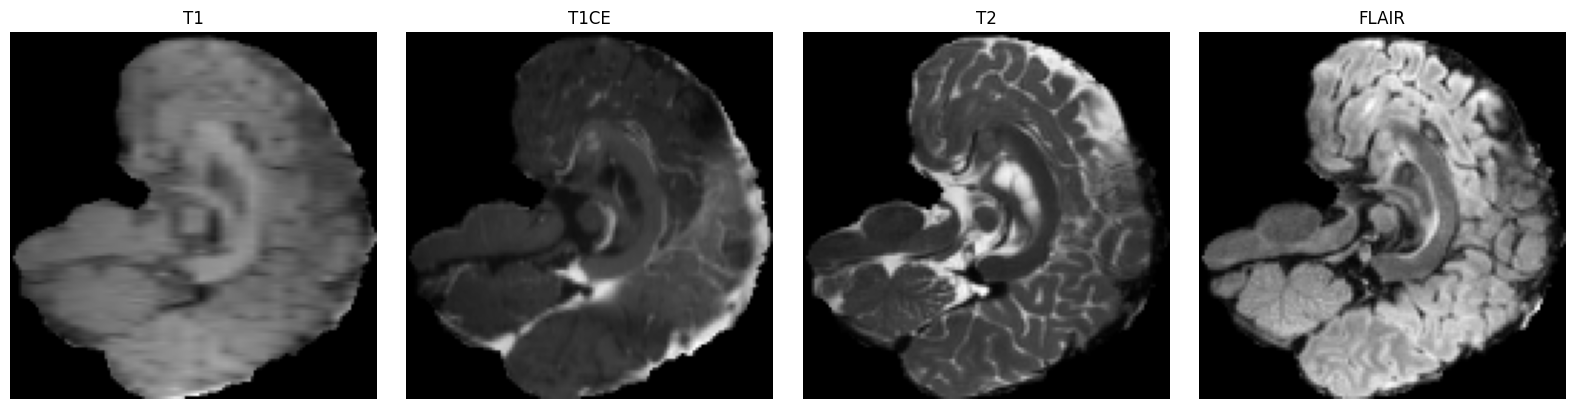

In [6]:
sample_id = PATIENT_IDS[0]
stack, seg_resampled = bts.preprocess_patient(sample_id, tar_path=TAR_PATH, local_root=LOCAL_ROOT, work_dir=WORK_DIR)
print("Preprocessed stack shape:", stack.shape)

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
mid = stack.shape[1] // 2
for i, m in enumerate(bts.MODALITIES):
    axes[i].imshow(stack[i, mid], cmap="gray")
    axes[i].set_title(m.upper())
    axes[i].axis("off")
plt.tight_layout()
plt.show()

In [13]:
import os
import re
import tarfile
import numpy as np
import nibabel as nib
import plotly.graph_objects as go
import plotly.io as pio
from scipy.ndimage import gaussian_filter
from skimage import measure

# Force Plotly to render inside Kaggle's iframe sandbox
pio.renderers.default = "iframe"

TAR_PATH = "/kaggle/input/datasets/dschettler8845/brats-2021-task1/BraTS2021_Training_Data.tar"
WORK_DIR = "/kaggle/working/brats_viewer"
os.makedirs(WORK_DIR, exist_ok=True)

def add_mesh(fig, volume, color, name, opacity):
    try:
        verts, faces, _, _ = measure.marching_cubes(volume, level=0.5, step_size=1)
        fig.add_trace(
            go.Mesh3d(
                x=verts[:, 2], y=verts[:, 1], z=verts[:, 0],
                i=faces[:, 0], j=faces[:, 1], k=faces[:, 2],
                color=color, opacity=opacity, name=name, showlegend=True,
                lighting=dict(ambient=0.4, diffuse=0.8, specular=0.2, roughness=0.5),
                lightposition=dict(x=100, y=200, z=150)
            )
        )
    except Exception:
        pass

# 1. Automatically locate and extract the first patient
patient_id = None
with tarfile.open(TAR_PATH, "r") as tar:
    for member in tar.getmembers():
        m = re.match(r"^\./(BraTS2021_\d{5})/", member.name)
        if m:
            patient_id = m.group(1)
            members = [x for x in tar.getmembers() if x.name.startswith(f"./{patient_id}/")]
            tar.extractall(path=WORK_DIR, members=members)
            break

print(f"Rendering 3D model for patient: {patient_id}")

# 2. Load NIfTI files
case_path = os.path.join(WORK_DIR, patient_id, patient_id)
t2 = nib.load(case_path + "_t2.nii.gz").get_fdata()
seg = nib.load(case_path + "_seg.nii.gz").get_fdata()

# 3. Process masks
raw_mri = (t2 - t2.min()) / (t2.max() - t2.min() + 1e-8)
brain = gaussian_filter((raw_mri > 0.15).astype(np.float32), sigma=1)
necrotic = (seg == 1).astype(np.float32)
edema = (seg == 2).astype(np.float32)
enhancing = (seg == 4).astype(np.float32)

# 4. Construct 3D scene
fig = go.Figure()
add_mesh(fig, brain, "#FFFFFF", "Brain Surface", 0.10)
add_mesh(fig, edema, "#00FF4D", "Edema Shell", 0.35)
add_mesh(fig, necrotic, "#FF004D", "Necrotic Core", 1.0)
add_mesh(fig, enhancing, "#00D0FF", "Enhancing Core", 1.0)

fig.update_layout(
    title=f"{patient_id} | Clinical 3D Reconstruction",
    paper_bgcolor="#050505",
    plot_bgcolor="#050505",
    font=dict(color="white"),
    margin=dict(l=0, r=0, b=0, t=40),
    showlegend=True,
    legend=dict(bgcolor="rgba(0,0,0,0.4)", bordercolor="white", borderwidth=1),
    scene=dict(
        xaxis=dict(title="Lateral", showgrid=False, showticklabels=False, showbackground=False, visible=False),
        yaxis=dict(title="Anterior", showgrid=False, showticklabels=False, showbackground=False, visible=False),
        zaxis=dict(title="Superior", showgrid=False, showticklabels=False, showbackground=False, visible=False),
        aspectmode="data",
        camera=dict(eye=dict(x=1.5, y=1.5, z=0.8))
    )
)

# 5. Display directly in Kaggle
fig.show(renderer="iframe")

/tmp/ipykernel_379/1474610435.py:41: DeprecationWarning:

Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.



Rendering 3D model for patient: BraTS2021_00000


In [8]:
TRAIN_PATIENTS = 16 if torch.cuda.is_available() else 4
EPOCHS = 10 if torch.cuda.is_available() else 2
CHECKPOINT_PATH = os.path.join(os.getcwd(), "artifacts", "best_unet.pt")

train_ids = PATIENT_IDS[:TRAIN_PATIENTS]
model, history = bts.train_unet3d(
    patient_ids=train_ids, epochs=EPOCHS, batch_size=1, lr=1e-3,
    val_split=0.2, tar_path=TAR_PATH, local_root=LOCAL_ROOT, work_dir=WORK_DIR,
    checkpoint_path=CHECKPOINT_PATH, device=device
)

Epoch 1/10 | train_loss=2.0393 | val_loss=15.2721 | WT Dice=0.0892
Epoch 2/10 | train_loss=1.7217 | val_loss=3.5339 | WT Dice=0.1137
Epoch 3/10 | train_loss=1.5620 | val_loss=1.5779 | WT Dice=0.7351
Epoch 4/10 | train_loss=1.4287 | val_loss=1.5056 | WT Dice=0.8030
Epoch 5/10 | train_loss=1.3149 | val_loss=1.2818 | WT Dice=0.8361
Epoch 6/10 | train_loss=1.2240 | val_loss=1.2603 | WT Dice=0.7028
Epoch 7/10 | train_loss=1.1587 | val_loss=1.2340 | WT Dice=0.7246
Epoch 8/10 | train_loss=1.0996 | val_loss=1.1752 | WT Dice=0.7772
Epoch 9/10 | train_loss=1.0470 | val_loss=1.0125 | WT Dice=0.8222
Epoch 10/10 | train_loss=0.9967 | val_loss=1.1531 | WT Dice=0.8032


In [9]:
model = bts.load_model(CHECKPOINT_PATH, device=device)
eval_ids = PATIENT_IDS[TRAIN_PATIENTS:TRAIN_PATIENTS+2]

for pid in eval_ids:
    pred, _, seg = bts.predict_patient(model, pid, tar_path=TAR_PATH, local_root=LOCAL_ROOT, work_dir=WORK_DIR, device=device)
    metrics = bts.evaluate_patient(pred, seg)
    print(f"\nPatient {pid}:")
    for r, m in metrics.items():
        print(f"  {r:15s} | Dice: {m['dice']:.4f} | Hausdorff: {m['hausdorff']:.2f}")


Patient BraTS2021_00022:
  Whole Tumor     | Dice: 0.8474 | Hausdorff: 10.63
  Tumor Core      | Dice: 0.7840 | Hausdorff: 18.79
  Enhancing Tumor | Dice: 0.6544 | Hausdorff: 12.21

Patient BraTS2021_00024:
  Whole Tumor     | Dice: 0.9122 | Hausdorff: 36.07
  Tumor Core      | Dice: 0.2459 | Hausdorff: 36.99
  Enhancing Tumor | Dice: 0.4594 | Hausdorff: 34.89
